# Feature (representation) distillation of a mobile VLM on GQA
### MobileVLM V2 **7B (teacher)** → MobileVLM V2 **3B (student)** · trained on the **largest available training tier** · Kaggle 2 × T4

| | |
|---|---|
| **Task** | Short-answer visual question answering (GQA balanced sample `v2_seed42`) |
| **Teacher / student** | MobileVLM V2 7B (frozen, fp16) / MobileVLM V2 3B + LoRA (r=16, α=32 on `q,k,v,o` of the LLM) |
| **Frozen in the student** | CLIP ViT-L/14@336, LDPv2 projector, embeddings, MLPs, `lm_head` |
| **Distillation signal** | Hidden-state alignment (answer position + visual tokens) added to the answer cross-entropy |
| **Training data** | the **largest** `train_<N>` file found in the dataset (`C["train_file"]="largest"`; set e.g. `"train_2000"` for a quick debug run) |
| **Evaluation** | `dev_mini` / `dev` (never trained on); `testdev` only once at the end |

## Method

For a question *x* with image *v*, let $h^{T}_\ell$, $h^{S}_\ell$ be the teacher / student hidden states after layer $\ell$ (both models have 32 layers, so layer $\ell$ ↔ layer $\ell$). Two kinds of positions are distilled:

* **answer position** $t^\*$: the last prompt token (`ASSISTANT:`), the position that emits the first answer token;
* **visual positions** $\mathcal V$: the 144 image tokens, average-pooled on their 12×12 grid to a $g\times g$ grid (default 4×4). The LLM is causal and the image precedes the question, so these states **do not depend on the question**: the teacher is run once per image for them.

The hidden sizes differ ($d_S=2560$, $d_T=4096$), so a small trainable adapter $A_\ell$ (LayerNorm + Linear) maps student → teacher space. It exists **only during training** and is discarded. Teacher features are z-scored per dimension on the training cache (Llama hidden states have outlier dimensions that would dominate a plain MSE): a loss of 1.0 means "explains nothing", $1-\text{loss}\approx$ explained variance.

$$\mathcal L=\mathrm{CE}(\text{answer tokens})+\lambda_q\,\frac{1}{|\mathcal L_q|}\sum_{\ell\in\mathcal L_q}\mathrm{MSE}\big(A_\ell(h^S_\ell[t^\*]),z(h^T_\ell[t^\*])\big)+\lambda_v\,\frac{1}{|\mathcal L_v|}\sum_{\ell\in\mathcal L_v}\mathrm{MSE}\big(A_\ell(\mathrm{pool}_g h^S_\ell[\mathcal V]),z(\mathrm{pool}_g h^T_\ell[\mathcal V])\big)$$

## Pipeline

```
 Phase 1 (teacher, fp16 over 2 GPUs)                  Phase 2 (student, 1 GPU)
 ┌───────────────────────────────────────┐   cache    ┌──────────────────────────────────────────┐
 │ train_N ─► MobileVLM V2 7B            │   (disk)   │ train_N ─► MobileVLM V2 3B + LoRA         │
 │  answer-pos states + pooled visual    ├──────────► │  CE on answer tokens                      │
 │  + teacher scores on dev_mini / dev   │            │  + λq·MSE(A(h_S), z(h_T)) answer position │
 │  + analysis features (for CKA)        │            │  + λv·MSE(A(h_S), z(h_T)) visual tokens   │
 └───────────────────────────────────────┘            └──────────────────────────────────────────┘
                              ▼  after training: teacher-vs-student comparison (cells 11-19)
```

## Experiment protocol
Same data, seed, data order and schedule for every run; **one factor changes per run** (`C["run"]`): `A_ce` (CE only, baseline) · `D_q` (+ answer-position features) · `D_v` (+ visual features) · `D_qv` (both, the proposed model). Reference rows are computed automatically: teacher, student zero-shot, "always yes".

## Teacher-vs-student comparison (final cells)
overall and per structural / semantic type · yes/no vs open answers · answer-frequency buckets · question length · agreement and error overlap · confidence and calibration (ECE, risk–coverage) · answer validity/verbosity · representation similarity (linear CKA per layer) · efficiency (params, FLOPs, memory, latency) · qualitative examples · cluster-bootstrap significance.

**Run order:** 1 → 2 → 3 → 4 (smoke test + cost projection, do not skip) → 5 → 6 → 7 → 8 → 9 → comparison cells. Every long phase is resumable: if a session ends, re-run cells 2 and 6, then the phase cell. With the whole training tier the job needs **several** sessions (see the projection in cell 4); set `C["session_minutes"]` to stop cleanly before Kaggle's session limit.

## 1. Environment
Internet must be **ON**. After this cell, if `transformers` was already imported in the session, **restart the session** and continue from cell 2.

MobileVLM was written for `transformers==4.33`; its nested CLIP `from_pretrained` breaks on `transformers>=5` (your error: *"meta device context manager"*). We pin a 4.x release that installs on recent Python and patch that one line so the vision tower is built from its config (equivalent: its weights come from the MobileVLM checkpoint anyway).

In [1]:
!pip install -q "transformers==4.49.0" "peft==0.14.0" "accelerate==1.3.0" sentencepiece timm pandas matplotlib
!test -d /kaggle/working/MobileVLM || git clone -q --depth 1 https://github.com/Meituan-AutoML/MobileVLM.git /kaggle/working/MobileVLM

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.0 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 10.0/10.0 MB 214.5 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 99.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.8/374.8 kB 19.7 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.6/336.6 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/566.4 kB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 3.1/3.1 MB 157.2 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 61.0 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import importlib.metadata as md, os, sys
from pathlib import Path

MV = Path(os.environ.get("MOBILEVLM_DIR", "/kaggle/working/MobileVLM"))
tv = md.version("transformers"); print("transformers on disk:", tv, "| peft:", md.version("peft"))
if "transformers" in sys.modules and sys.modules["transformers"].__version__ != tv:
    raise RuntimeError("transformers was already imported with another version: restart the session, then run from cell 2.")
if not tv.startswith("4."):
    print("WARNING: transformers>=5 is not supported by MobileVLM's tokenizer/model code; expect problems.")

# MobileVLM builds a "dummy" CLIP via a *nested* from_pretrained inside the outer from_pretrained.
# Its weights are loaded from the MobileVLM checkpoint afterwards, so building it from the config is equivalent.
f = MV / "mobilevlm/model/vision_encoder.py"; src = f.read_text()
OLD = "self.vision_tower = CLIPVisionModel.from_pretrained(self.vision_tower_name)  # dummy-load"
NEW = "self.vision_tower = CLIPVisionModel(self.cfg_only)  # dummy-load (patched: build from config)"
if OLD in src:   f.write_text(src.replace(OLD, NEW)); print("vision_encoder.py patched")
elif NEW in src: print("vision_encoder.py already patched")
else: raise RuntimeError("vision_encoder.py changed upstream: inspect CLIPVisionTower.__init__")

transformers on disk: 4.49.0 | peft: 0.14.0
vision_encoder.py patched


## 2. Imports, configuration, helpers

In [3]:
import gc, json, math, re, time, random, shutil, subprocess
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
os.environ["TOKENIZERS_PARALLELISM"] = "false"

sys.path.insert(0, str(MV))
from mobilevlm.model.mobilevlm import load_pretrained_model
from mobilevlm.conversation import conv_templates
from mobilevlm.utils import process_images, tokenizer_image_token
from mobilevlm.constants import IMAGE_TOKEN_INDEX
# NOTE: we deliberately do NOT call mobilevlm.utils.disable_torch_init(): it permanently turns
# nn.Linear / nn.LayerNorm initialisation into a no-op (our adapters would start with garbage).

CUDA = torch.cuda.is_available(); NGPU = torch.cuda.device_count()
DEV  = "cuda:0" if CUDA else "cpu"
MDT  = torch.float16 if CUDA else torch.float32        # T4 has no bf16

def find_dataset():
    if os.environ.get("GQA_DIR"): return Path(os.environ["GQA_DIR"])
    for pat in ("*/stats.json", "*/*/stats.json", "*/*/*/stats.json"):
        for h in Path("/kaggle/input").glob(pat):
            if (h.parent / "dev_mini.json").exists(): return h.parent
    raise FileNotFoundError("GQA sample not found under /kaggle/input: attach the dataset or set D manually")
#D = str(find_dataset()); sys.path.append(D)
D="/kaggle/input/datasets/djihadelhakbelkhir/gqa-kd/gqa_v2_seed42" ; sys.path.append(D)
import gqa_utils
from gqa_utils import SUFFIX, evaluate                  # shipped with the dataset
normalize = getattr(gqa_utils, "normalize", lambda t: " ".join(str(t).lower().strip().strip(".,!?;:\"'").split()))
print("dataset:", D, "| GPUs:", NGPU, [torch.cuda.get_device_name(i) for i in range(NGPU)])

def resolve_train_file(name):
    """'largest' -> the biggest train_<N>.json of the sample (the 'whole dataset')."""
    tiers = sorted((int(m.group(1)), p.stem) for p in Path(D).glob("train_*.json") if (m := re.fullmatch(r"train_(\d+)", p.stem)))
    print("available training tiers:", tiers)
    if name != "largest": return name
    assert tiers, "no train_<N>.json found"
    return tiers[-1][1]

# ------------------------------------------------------------------ configuration
PRESETS = {"A_ce": (0.0, 0.0), "D_q": (1.0, 0.0), "D_v": (0.0, 1.0), "D_qv": (1.0, 1.0)}   # (lam_q, lam_v)
OVERRIDES = globals().get("OVERRIDES", {})              # only used by automated smoke tests
C = dict(
    run="D_qv",                                         # <-- choose the experiment
    teacher="mtgv/MobileVLM_V2-7B", student="mtgv/MobileVLM_V2-3B",
    train_file="largest", dev_mini="dev_mini", dev="dev",
    max_q_per_image=5,              # cap questions per training image (seeded random choice); None = all
    # ---- shared student configuration (identical for ALL runs) ----
    seed=42, epochs=1, micro_bs=1, grad_accum=16,
    lr=2e-4, wd=0.0, warmup_ratio=0.03, max_grad_norm=1.0,
    lora_r=16, lora_alpha=32, lora_dropout=0.05,
    conv_mode="v1", max_seq_len=1024, max_new_tokens=16,
    # ---- feature-distillation design (identical for all D_* runs); sized for the 20 GB /kaggle/working limit ----
    q_layers=[16, 32],              # answer-position layers (teacher layer l <-> student layer l)
    v_layers=[16, 32],              # visual-token layers
    v_grid=4,                       # 12x12 visual grid -> 4x4 pooled tokens
    expect_vis=144,                 # visual tokens per image (LDPv2)
    # ---- evaluation / analysis ----
    eval_splits=["dev_mini", "dev"],            # trained student
    eval_teacher_splits=["dev_mini", "dev"],    # teacher reference rows
    eval_zeroshot_splits=["dev_mini", "dev"],   # untouched student reference rows
    cka_n=800, cka_layers=[4, 8, 12, 16, 20, 24, 28, 32],    # representation-similarity analysis
    # ---- engineering ----
    grad_ckpt=False,                # set True only if you hit OOM
    ckpt_every=250,                 # optimizer steps between resumable checkpoints
    session_minutes=None,           # e.g. 11*60: stop cleanly (checkpointed) before Kaggle's session limit
    export_merged="auto",           # True/False/"auto" (auto = only the D_qv run): standalone merged fp16 student (~6 GB)
    disk_margin_gb=8,               # free space required on top of the teacher cache
)
C["lam_q"], C["lam_v"] = PRESETS[C["run"]]
C.update(OVERRIDES)
C["train_file"] = resolve_train_file(C["train_file"])
assert C["epochs"] == 1 and C["micro_bs"] == 1, "the loop is written for 1 epoch, micro-batch 1"

WORK  = Path(os.environ.get("WORK_DIR", "/kaggle/working")) / "kd_gqa"
CACHE = WORK / "teacher_cache" / C["train_file"]
BASE  = WORK / "baselines"
RUN   = WORK / "runs" / C["run"]
for p in (CACHE, BASE, RUN): p.mkdir(parents=True, exist_ok=True)
USE_Q, USE_V = C["lam_q"] > 0, C["lam_v"] > 0
DEADLINE = time.time() + 60 * C["session_minutes"] if C["session_minutes"] else None
def out_of_time(): return DEADLINE is not None and time.time() > DEADLINE
print(f"run={C['run']}  train={C['train_file']}  lam_q={C['lam_q']}  lam_v={C['lam_v']}  | outputs -> {WORK}")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
seed_all(C["seed"])

# ------------------------------------------------------------------ model / prompt helpers
def amp():   # fp16 autocast on GPU, no-op on CPU
    return torch.autocast(device_type="cuda" if CUDA else "cpu", dtype=torch.float16, enabled=CUDA)
def sync():
    if CUDA: [torch.cuda.synchronize(i) for i in range(NGPU)]
def mdtype(m): return m.get_model().embed_tokens.weight.dtype

def load_vlm(path, device_map):
    """device_map='auto' -> split over all GPUs (teacher); {'':0} -> everything on cuda:0 (student)."""
    if not CUDA: device_map = {"": "cpu"}
    if device_map == "auto" and NGPU >= 2:        # keep embeddings + CLIP + projector together on GPU 0, split the 32 LLM layers
        device_map = {"model.embed_tokens": 0, "model.vision_tower": 0, "model.mm_projector": 0, "model.rotary_emb": 0,
                      **{f"model.layers.{i}": (0 if i < 16 else 1) for i in range(32)}, "model.norm": 1, "lm_head": 1}
    tok, model, proc, _ = load_pretrained_model(path, load_8bit=False, load_4bit=False,
                                                device_map=device_map, device=DEV)
    return tok, model.to(dtype=MDT), proc

def build_prompt(human_value, answer=None):
    """v1 template. answer=None -> '... ASSISTANT:'   answer='yes' -> '... ASSISTANT: yes</s>'"""
    conv = conv_templates[C["conv_mode"]].copy()
    conv.append_message(conv.roles[0], human_value)     # '<image>' newline question newline SUFFIX (as stored)
    conv.append_message(conv.roles[1], answer)
    return conv.get_prompt()

def encode(tok, rec):
    human, ans = rec["conversations"][0]["value"], rec["conversations"][1]["value"]
    p = tokenizer_image_token(build_prompt(human), tok, IMAGE_TOKEN_INDEX, return_tensors="pt")
    f = tokenizer_image_token(build_prompt(human, ans), tok, IMAGE_TOKEN_INDEX, return_tensors="pt")
    assert torch.equal(f[:len(p)], p), "prompt/answer tokenisation boundary mismatch"
    a = f[len(p):]
    assert a.numel() >= 2 and int(a[-1]) == tok.eos_token_id, "answer must end with </s>"
    return p, f, a                       # prompt ids | full ids | answer ids (answer tokens + </s>)

def spans(ids, L_exp, n_ans=0):
    """Single source of truth for positions in the *expanded* sequence (visual tokens spliced in).
    ids: [1, L_ids] with one IMAGE placeholder; L_exp: expanded length; n_ans: answer tokens at the end."""
    p = int((ids[0] == IMAGE_TOKEN_INDEX).nonzero()[0])  # first visual token
    n_vis = L_exp - (ids.shape[1] - 1)                   # placeholder replaced by n_vis tokens
    pos = L_exp - n_ans - 1                              # last prompt token: predicts answer[0]
    return p, n_vis, pos

def pool_visual(x, grid):
    """[n_vis, d] (row-major g x g grid) -> [grid*grid, d] fp32. Used identically for teacher and student."""
    n, d = x.shape; g = math.isqrt(n); assert g * g == n
    x = x.float().T.reshape(1, d, g, g)
    return F.adaptive_avg_pool2d(x, grid)[0].flatten(1).T

def rows_of(name): return json.load(open(f"{D}/{name}.json"))

class GQADS(Dataset):
    """Image + token preprocessing runs in DataLoader workers (CPU only)."""
    def __init__(self, rows, tok, proc, mcfg): self.rows, self.tok, self.proc, self.mcfg = rows, tok, proc, mcfg
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = Image.open(f"{D}/{r['image']}").convert("RGB")
        pix = process_images([img], self.proc, self.mcfg)[0]
        p, f, a = encode(self.tok, r)
        assert f.numel() + C["expect_vis"] - 1 <= C["max_seq_len"]
        return dict(id=r["id"], image_id=Path(r["image"]).stem, pix=pix, prompt_ids=p, full_ids=f, ans_ids=a)

def train_rows():
    """Training questions actually used (teacher cache AND student training): <= max_q_per_image per image, seeded."""
    rows, K = rows_of(C["train_file"]), C["max_q_per_image"]
    if not K: return rows
    by_img = {}
    for r in rows: by_img.setdefault(r["image"], []).append(r)
    rng, out = random.Random(C["seed"]), []
    for img in sorted(by_img):
        rs = by_img[img]; out += rs if len(rs) <= K else rng.sample(rs, K)
    return out

class ImageDS(Dataset):
    """One item = one image + all its selected questions (shared prefix, per-question suffix)."""
    def __init__(self, groups, tok, proc, mcfg): self.groups, self.tok, self.proc, self.mcfg = groups, tok, proc, mcfg
    def __len__(self): return len(self.groups)
    def __getitem__(self, k):
        rs = self.groups[k]
        img = Image.open(f"{D}/{rs[0]['image']}").convert("RGB")
        pix = process_images([img], self.proc, self.mcfg)[0]
        pre, suf = None, []
        for r in rs:
            p_ids = encode(self.tok, r)[0]; j = int((p_ids == IMAGE_TOKEN_INDEX).nonzero()[0])
            if pre is None: pre = p_ids[:j]                       # text before the image placeholder
            assert torch.equal(p_ids[:j], pre), "prefix differs between questions of one image"
            suf.append(p_ids[j + 1:])                             # text after the image: question + suffix + 'ASSISTANT:'
        return dict(image_id=Path(rs[0]["image"]).stem, pix=pix, prefix_ids=pre, qids=[r["id"] for r in rs], suffix_ids=suf)

def load_pix(model, proc, r):
    img = Image.open(f"{D}/{r['image']}").convert("RGB")
    return process_images([img], proc, model.config).to(model.device, mdtype(model))

# ------------------------------------------------------------------ decoding + evaluation
@torch.no_grad()
def greedy_decode(model, ids, pix, eos_id, max_new):
    """Greedy decoding WITHOUT a KV cache (MobileVLM's generate() relies on the legacy cache format and breaks on
    recent transformers; answers are 1-3 tokens so the extra forward passes are cheap).
    Returns (generated token ids, confidence = top-1 probability of the first generated token)."""
    cur, new, conf = ids, [], float("nan")
    for step in range(max_new):
        with amp():
            logits = model(input_ids=cur, images=pix, use_cache=False).logits[0, -1].float()
        pr = torch.softmax(logits, -1); nxt = int(pr.argmax())
        if step == 0: conf = float(pr[nxt])
        if nxt == eos_id: break
        new.append(nxt); cur = torch.cat([cur, torch.tensor([[nxt]], device=cur.device)], 1)
    return new, conf

@torch.no_grad()
def run_eval(model, tok, proc, rows, part_path=None, desc="eval"):
    """Single-turn, greedy, same prompt as training. `model` = plain MobileLlama model (not the peft wrapper)."""
    model.eval()
    store = json.load(open(part_path)) if part_path and Path(part_path).exists() else {}   # id -> [text, conf]
    lat = []
    for r in tqdm([r for r in rows if r["id"] not in store], desc=desc):
        pix = load_pix(model, proc, r); ids = encode(tok, r)[0][None].to(model.device)
        sync(); t0 = time.perf_counter()
        new, conf = greedy_decode(model, ids, pix, tok.eos_token_id, C["max_new_tokens"])
        sync(); lat.append(time.perf_counter() - t0)
        store[r["id"]] = [tok.decode(new, skip_special_tokens=True).strip(), conf]
        if part_path and len(lat) % 500 == 0: json.dump(store, open(part_path, "w"))
    if part_path: json.dump(store, open(part_path, "w"))
    preds = {k: v[0] for k, v in store.items()}; confs = {k: v[1] for k, v in store.items()}
    return evaluate(preds, rows), preds, confs, (1000 * float(np.mean(lat)) if lat else float("nan"))

def eval_split(tag, model, tok, proc, split, outdir):
    """Idempotent: res_/preds_/conf_<tag>_<split>.json are cached on disk (partial results flushed every 500 questions)."""
    outdir = Path(outdir); rf, pf, cf = (outdir / f"{k}_{tag}_{split}.json" for k in ("res", "preds", "conf"))
    if rf.exists() and pf.exists() and cf.exists(): return json.load(open(rf)), json.load(open(pf))
    res, preds, confs, ms = run_eval(model, tok, proc, rows_of(split), part_path=str(pf) + ".part", desc=f"{tag}/{split}")
    res = dict(res, latency_ms_per_q=ms, split=split, tag=tag)
    json.dump(preds, open(pf, "w")); json.dump(confs, open(cf, "w")); json.dump(res, open(rf, "w"))
    Path(str(pf) + ".part").unlink(missing_ok=True)
    return res, preds

# ------------------------------------------------------------------ representation analysis helpers
@torch.no_grad()
def extract_feats(model, tok, proc, rows, layers):
    """Answer-position state and mean visual-token state at the given layers, for the fixed analysis subset."""
    model.eval(); q, v = [], []
    for r in tqdm(rows, desc="analysis features"):
        pix = load_pix(model, proc, r); ids = encode(tok, r)[0][None].to(model.device)
        with amp(): hs = model(input_ids=ids, images=pix, output_hidden_states=True, use_cache=False).hidden_states
        p, n_vis, pos = spans(ids, hs[0].shape[1])
        q.append(torch.stack([hs[l][0, pos].float().cpu() for l in layers]))
        v.append(torch.stack([hs[l][0, p:p + n_vis].float().mean(0).cpu() for l in layers]))
    return dict(q=torch.stack(q).half(), v=torch.stack(v).half(), ids=[r["id"] for r in rows], layers=list(layers))

def feats_cached(tag, model, tok, proc, outdir):
    f = Path(outdir) / f"feats_{tag}.pt"
    if not f.exists(): torch.save(extract_feats(model, tok, proc, rows_of(C["dev_mini"])[:C["cka_n"]], C["cka_layers"]), f)

def linear_cka(X, Y):
    """Linear CKA (Kornblith et al. 2019) via Gram matrices; works for different widths (2560 vs 4096)."""
    X = X.float() - X.float().mean(0); Y = Y.float() - Y.float().mean(0)
    K, L = X @ X.T, Y @ Y.T
    return float((K * L).sum() / (K.norm() * L.norm() + 1e-12))

def fmt(res): return {k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()}
def n_params(m): return sum(p.numel() for p in m.parameters())

dataset: /kaggle/input/datasets/djihadelhakbelkhir/gqa-kd/gqa_v2_seed42 | GPUs: 2 ['Tesla T4', 'Tesla T4']
available training tiers: [(2000, 'train_2000'), (5000, 'train_5000'), (10000, 'train_10000'), (20000, 'train_20000')]
run=D_qv  train=train_20000  lam_q=1.0  lam_v=1.0  | outputs -> /kaggle/working/kd_gqa


## 3. Data integrity checks
Fails loudly if the sample is not what the protocol assumes: image-disjoint splits, identical prompt suffix, evaluator sanity, image files present.

dataset version: v2_seed42 | seed: 42


train_20000  questions= 262617  images= 20000
dev_mini     questions=   3874  images=   300
dev          questions=  13174  images=  1000


trivial 'always yes' baseline on dev: 0.1772


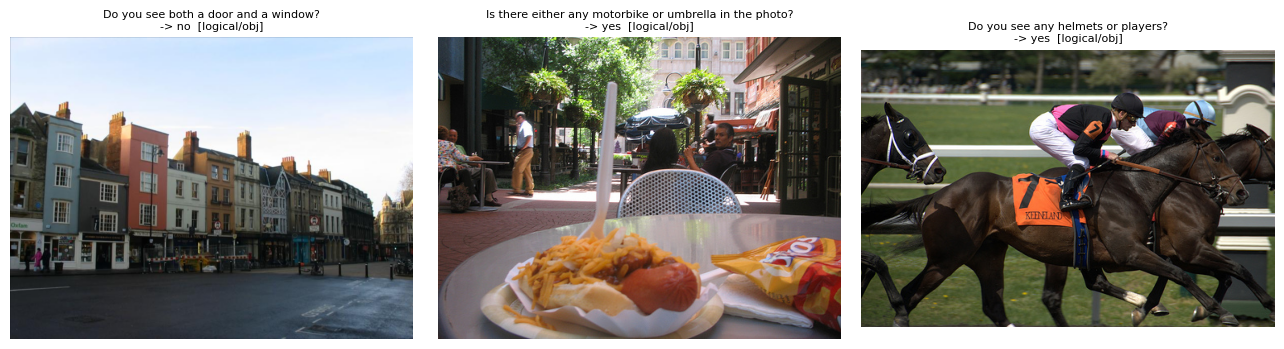

In [4]:
stats = json.load(open(f"{D}/stats.json"))
print("dataset version:", stats["version"], "| seed:", stats["seed"])
rows_train, rows_dm, rows_dev = rows_of(C["train_file"]), rows_of(C["dev_mini"]), rows_of(C["dev"])
for name, rr in ((C["train_file"], rows_train), (C["dev_mini"], rows_dm), (C["dev"], rows_dev)):
    cnt = stats["counts"].get(name, {})
    if "questions" in cnt: assert cnt["questions"] == len(rr), (name, cnt["questions"], len(rr))
    print(f"{name:12s} questions={len(rr):7d}  images={len({r['image'] for r in rr}):6d}")

imgs = lambda rr: {r["image"] for r in rr}
rows_test = rows_of("testdev")                                   # leakage check only, never used for tuning
assert not imgs(rows_train) & imgs(rows_dev) and not imgs(rows_train) & imgs(rows_test) and not imgs(rows_dev) & imgs(rows_test), "image leakage!"
assert imgs(rows_dm) <= imgs(rows_dev)
del rows_test
assert all(r["conversations"][0]["value"].endswith(SUFFIX) for r in rows_train + rows_dev), "prompt suffix mismatch"
assert all(r["conversations"][0]["value"].startswith("<image>\n") for r in rows_train[:1000])
assert evaluate({r["id"]: r["conversations"][1]["value"] for r in rows_dev}, rows_dev)["all"] == 1.0, "evaluator sanity failed"
missing = [r["image"] for r in rows_train + rows_dev if not os.path.exists(f"{D}/{r['image']}")]
assert not missing, f"{len(missing)} image files missing, e.g. {missing[:3]}"

yes_res = evaluate({r["id"]: "yes" for r in rows_dev}, rows_dev)
json.dump(dict(yes_res, tag="always_yes", split=C["dev"]), open(BASE / f"res_always_yes_{C['dev']}.json", "w"))
print("trivial 'always yes' baseline on dev:", round(yes_res["all"], 4))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))                 # always look at a few samples
for ax, r in zip(axs, random.Random(0).sample(rows_train, 3)):
    ax.imshow(Image.open(f"{D}/{r['image']}").convert("RGB")); ax.axis("off")
    q = r["conversations"][0]["value"].replace("<image>\n", "").replace(SUFFIX, "").strip()
    ax.set_title(f"{q}\n-> {r['conversations'][1]['value']}  [{r['meta']['structural']}/{r['meta']['semantic']}]", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Smoke test + cost projection (do not skip)
Verifies on the real student every assumption the pipeline relies on (tokenisation boundary, `</s>`, 144 visual tokens, hidden-state count, causality of the visual cache), then **measures throughput** and projects the wall-clock time and disk footprint of the chosen training tier before you commit GPU quota.

In [5]:
tok, S0, proc = load_vlm(C["student"], {"": 0})
r = rows_dm[0]
p_ids, f_ids, a_ids = encode(tok, r)
print("prompt  :", tok.decode([i for i in p_ids.tolist() if i >= 0])[-90:])
print("answer  :", repr(tok.decode(a_ids)), "| GT:", r["conversations"][1]["value"])

pix = load_pix(S0, proc, r)
with torch.no_grad(), amp():
    out = S0(input_ids=f_ids[None].to(DEV), images=pix, output_hidden_states=True, use_cache=False)
L = out.hidden_states[0].shape[1]
p, n_vis, pos = spans(f_ids[None], L, n_ans=a_ids.numel())
nl = S0.config.num_hidden_layers
print(f"hidden tensors={len(out.hidden_states)} (expect {nl+1}) | expanded seq={L} | visual tokens={n_vis} (expect {C['expect_vis']})"
      f" | hidden={out.hidden_states[-1].shape[-1]} | layers={nl} | answer-pos={pos}")
assert len(out.hidden_states) == nl + 1 and n_vis == C["expect_vis"]
assert max(C["q_layers"] + C["v_layers"] + C["cka_layers"]) <= nl
# causality check behind the visual-token cache: visual states must not depend on the question / answer
with torch.no_grad(), amp():
    hp = S0(input_ids=p_ids[None].to(DEV), images=pix, output_hidden_states=True, use_cache=False).hidden_states
l = C["v_layers"][0]
d = (hp[l][0, p:p + n_vis].float() - out.hidden_states[l][0, p:p + n_vis].float()).abs().max().item()
dq = (hp[l][0, -1].float() - out.hidden_states[l][0, pos].float()).abs().max().item()
print(f"max |visual states: prompt-only vs prompt+answer| = {d:.2e} | answer-position states = {dq:.2e}  (both should be tiny: fp16 noise only)")

# ---- throughput measurement on 12 training questions (forward only; training ~3x, teacher ~2.5x a student forward)
sub = rows_train[:12]; ts = []
for r in sub:
    pix = load_pix(S0, proc, r); ids = encode(tok, r)[1][None].to(DEV); sync(); t0 = time.perf_counter()
    with torch.no_grad(), amp(): S0(input_ids=ids, images=pix, use_cache=False)
    sync(); ts.append(time.perf_counter() - t0)
t_fwd = float(np.median(ts[2:]))                      # skip warm-up
res, preds, confs, ms = run_eval(S0, tok, proc, rows_dm[:20])
print("8 predictions:", [(preds[x["id"]], x["conversations"][1]["value"]) for x in rows_dm[:8]])
print(f"acc on 20 = {res['all']:.2f} | invalid = {res['invalid_rate']:.2f} | {ms:.0f} ms/question decode | student forward {1000*t_fwd:.0f} ms")

_tr = train_rows(); Nq, Ni = len(_tr), len({r["image"] for r in _tr})
H = lambda sec: f"{sec/3600:.1f} h"
t_teach = Ni * t_fwd * 2.6 + Nq * 0.03; t_train = Nq * t_fwd * 3.2     # teacher: 1 prefix pass per image + ~30 ms/question (batched suffixes)
t_ev = lambda n: n * ms / 1000 * 2.4
cache_gb = (Nq * len(C["q_layers"]) * 4096 * 2 + Ni * len(C["v_layers"]) * C["v_grid"] ** 2 * 4096 * 2) / 2**30
free_gb = shutil.disk_usage(WORK).free / 2**30
print(f"\n=== projection for '{C['train_file']}' ({Nq} questions, {Ni} images) - rough, measure with the progress bars ===")
print(f"teacher feature cache ~ {H(t_teach)} | training ~ {H(t_train)} | teacher dev eval ~ {H(t_ev(len(rows_dev)))} "
      f"| student dev eval ~ {H(t_ev(len(rows_dev)))} (x2 for zero-shot + trained)")
print(f"teacher cache on disk ~ {cache_gb:.1f} GB | free disk {free_gb:.1f} GB | Kaggle: 12 h per session, ~30 GPU h per week")
assert cache_gb + C["disk_margin_gb"] < free_gb, "not enough disk for the cache + merged model: use a smaller tier or fewer/lower-resolution layers"
del S0, out, hp; gc.collect(); torch.cuda.empty_cache() if CUDA else None

tokenizer_config.json:   0%|          | 0.00/824 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/6.03G [00:00<?, ?B/s]

...

hidden tensors=33 (expect 33) | expanded seq=208 | visual tokens=144 (expect 144) | hidden=2560 | layers=32 | answer-pos=204


max |visual states: prompt-only vs prompt+answer| = 0.00e+00 | answer-position states = 0.00e+00  (both should be tiny: fp16 noise only)


eval:   0%|          | 0/20 [00:00<?, ?it/s]

8 predictions: [('Jeans', 'jeans'), ('Jeans', 'jeans'), ('Top', 'top'), ('Man', 'man'), ('No', 'no'), ('No', 'no'), ('Dog', 'dog'), ('Dog', 'dog')]
acc on 20 = 0.90 | invalid = 0.00 | 212 ms/question decode | student forward 97 ms



=== projection for 'train_20000' (90561 questions, 20000 images) - rough, measure with the progress bars ===
teacher feature cache ~ 2.2 h | training ~ 7.8 h | teacher dev eval ~ 1.9 h | student dev eval ~ 1.9 h (x2 for zero-shot + trained)
teacher cache on disk ~ 6.3 GB | free disk 19.5 GB | Kaggle: 12 h per session, ~30 GPU h per week


## 5. Phase 1: teacher features (resumable, sharded) + teacher reference scores + analysis features
Only the feature cache is specific to `D_*` runs; the teacher's own scores and analysis features are reference material for **every** run. Skipped automatically when already on disk. The cache is bound to its config (`meta.json`): changing layers, grid, teacher or prompt raises an error instead of silently mixing caches. With `session_minutes` set, the phase stops cleanly (shard flushed) and resumes on re-run.

In [6]:
@torch.no_grad()
def cache_teacher():
    rows = train_rows()
    meta_now = dict(teacher=C["teacher"], train_file=C["train_file"], q_layers=C["q_layers"], v_layers=C["v_layers"],
                    v_grid=C["v_grid"], conv_mode=C["conv_mode"], suffix=SUFFIX)
    if (CACHE / "meta.json").exists():
        old = json.load(open(CACHE / "meta.json"))
        bad = {k: (old.get(k), v) for k, v in meta_now.items() if old.get(k) != v}
        assert not bad, f"teacher cache was built with a different config {bad}: use another WORK dir or delete {CACHE}"

    done_q, seen_img = set(), set()
    for f in sorted(CACHE.glob("shard_*.pt")):                      # sidecar ids: no need to read GBs of tensors
        side = f.with_suffix(".ids.json")
        s = json.load(open(side)) if side.exists() else (lambda z: dict(qids=z["qids"], img_ids=z["img_ids"]))(torch.load(f))
        done_q |= set(s["qids"]); seen_img |= set(s["img_ids"])
    shard_id = len(list(CACHE.glob("shard_*.pt")))
    todo = [r for r in rows if r["id"] not in done_q]
    need_eval = [s for s in C["eval_teacher_splits"] if not all((BASE / f"{k}_teacher_{s}.json").exists() for k in ("res", "preds", "conf"))]
    need_an = not (BASE / "feats_teacher.pt").exists()
    need_feats = bool(todo) and (USE_Q or USE_V)
    if not (need_feats or need_eval or need_an):
        print("nothing to do: teacher cache / baselines / analysis features are complete (or not needed for this run)"); return "complete"
    json.dump(meta_now, open(CACHE / "meta.json", "w"))

    tok, T, proc = load_vlm(C["teacher"], "auto")                  # fp16, split over both T4s
    if CUDA: assert next(T.parameters()).device.type == "cuda", "teacher landed on CPU"
    T.eval(); nl = T.config.num_hidden_layers
    assert max(C["q_layers"] + C["v_layers"] + C["cka_layers"]) <= nl
    json.dump(dict(params=n_params(T), layers=nl, hidden=T.config.hidden_size, name=C["teacher"]), open(WORK / "teacher_info.json", "w"))

    if need_feats:
        print(f"{len(done_q)} questions cached, {len(todo)} to go")
        buf = dict(qids=[], q=[], img_ids=[], v=[])
        def flush():
            nonlocal shard_id, buf
            if not buf["qids"]: return
            name = CACHE / f"shard_{shard_id:06d}"
            json.dump(dict(qids=buf["qids"], img_ids=buf["img_ids"]), open(str(name) + ".ids.json", "w"))
            torch.save(dict(qids=buf["qids"], q=torch.stack(buf["q"]),                 # [n, n_ql, d_T] fp16
                            img_ids=buf["img_ids"],
                            v=torch.stack(buf["v"]) if buf["v"] else torch.empty(0)),  # [n_img, n_vl, g*g, d_T] fp16
                       str(name) + ".pt")
            shard_id += 1; buf = dict(qids=[], q=[], img_ids=[], v=[])

        by_img = {}
        for r in todo: by_img.setdefault(r["image"], []).append(r)
        dl = DataLoader(ImageDS(list(by_img.values()), tok, proc, T.config), batch_size=None, shuffle=False, num_workers=2, prefetch_factor=2)
        pbar = tqdm(total=len(todo), desc="teacher features"); tm = T.get_model()
        for b in dl:
            n_q = len(b["qids"])
            pix = b["pix"][None].to(T.device, mdtype(T))
            pre = b["prefix_ids"][None].to(T.device)                # text before the image placeholder (identical for all questions)
            with amp():                                             # (1) shared prefix: system prompt + image, ONE pass per image
                img_f = T.encode_images(pix)                        # [1, 144, d]
                emb = torch.cat([tm.embed_tokens(pre), img_f.to(tm.embed_tokens.weight.dtype)], 1)
                o = tm(inputs_embeds=emb, use_cache=True, output_hidden_states=True, return_dict=True)
            p, n_vis = pre.shape[1], img_f.shape[1]; assert n_vis == C["expect_vis"]
            if b["image_id"] not in seen_img:                       # visual features, once per image (causal: question-independent)
                buf["img_ids"].append(b["image_id"]); seen_img.add(b["image_id"])
                buf["v"].append(torch.stack([pool_visual(o.hidden_states[l][0, p:p + n_vis].cpu(), C["v_grid"]).half()
                                             for l in C["v_layers"]]))
            suf = b["suffix_ids"]; lens = [s.numel() for s in suf]  # (2) all question suffixes of this image in ONE batched pass
            sid = torch.zeros(n_q, max(lens), dtype=torch.long)     # RIGHT padding: causal attention => real positions unaffected
            for k, s in enumerate(suf): sid[k, :s.numel()] = s
            cache = o.past_key_values; cache.batch_repeat_interleave(n_q)
            with amp():
                o2 = tm(inputs_embeds=tm.embed_tokens(sid.to(T.device)), past_key_values=cache, use_cache=True,
                        output_hidden_states=True, return_dict=True)
            for k in range(n_q):                                    # answer-position state = last real suffix token
                buf["qids"].append(b["qids"][k])
                buf["q"].append(torch.stack([o2.hidden_states[l][k, lens[k] - 1].float().cpu() for l in C["q_layers"]]).half())
            pbar.update(n_q)
            if len(buf["qids"]) >= 1000: flush()                    # checkpoint every ~1000 questions
            if out_of_time():
                flush(); print("session budget reached: shard saved, re-run this cell to continue"); return "partial"
        flush(); pbar.close()

    for s in need_eval:                                            # teacher reference rows
        res, _ = eval_split("teacher", T, tok, proc, s, BASE); print("TEACHER", s, fmt(res))
        if out_of_time(): print("session budget reached: re-run this cell to continue"); return "partial"
    if need_an: feats_cached("teacher", T, tok, proc, BASE)
    del T; gc.collect(); torch.cuda.empty_cache() if CUDA else None
    return "complete"

CACHE_STATUS = cache_teacher(); print("status:", CACHE_STATUS)

tokenizer_config.json:   0%|          | 0.00/828 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin.index.json: 0.00B [00:00, ?B/s]

...

TEACHER dev_mini {'all': 0.723, 'query': 0.5962, 'sem:cat': 0.6773, 'choose': 0.8781, 'sem:attr': 0.7959, 'sem:rel': 0.6365, 'verify': 0.8481, 'logical': 0.8831, 'sem:obj': 0.8781, 'compare': 0.7426, 'sem:global': 0.7686, 'n': 3874, 'invalid_rate': 0.0, 'latency_ms_per_q': 525.3877, 'split': 'dev_mini', 'tag': 'teacher'}


teacher/dev:   0%|          | 0/13174 [00:00<?, ?it/s]

TEACHER dev {'all': 0.7167, 'query': 0.5859, 'sem:cat': 0.6873, 'choose': 0.8747, 'sem:attr': 0.7722, 'sem:rel': 0.6411, 'verify': 0.8665, 'logical': 0.8736, 'sem:obj': 0.8884, 'compare': 0.7105, 'sem:global': 0.7083, 'n': 13174, 'invalid_rate': 0.0, 'latency_ms_per_q': 528.7045, 'split': 'dev', 'tag': 'teacher'}


analysis features:   0%|          | 0/800 [00:00<?, ?it/s]

status: complete


## 6. Phase 2: student, zero-shot reference, LoRA, feature adapters

In [7]:
assert CACHE_STATUS == "complete", "teacher phase unfinished: re-run cell 5 until it reports 'complete'"
def zstats(T_, chunk=4096):
    """T_: [N, K, (..), d] fp16 -> per-layer, per-dimension mean / std over all other axes ([K, d] each), chunked."""
    mu, sd = [], []
    for k in range(T_.shape[1]):
        s1 = s2 = 0.; n = 0
        for a in range(0, T_.shape[0], chunk):
            x = T_[a:a + chunk, k].float().reshape(-1, T_.shape[-1]).double()
            s1 = s1 + x.sum(0); s2 = s2 + (x * x).sum(0); n += x.shape[0]
        m = s1 / n; mu.append(m.float()); sd.append((s2 / n - m * m).clamp_min(0).sqrt().float().clamp_min(1e-4))
    return torch.stack(mu).to(DEV), torch.stack(sd).to(DEV)

rows = train_rows(); D_T = None
if USE_Q or USE_V:
    info = json.load(open(WORK / "teacher_info.json"))
    qids, iids, Qs, Vs = [], [], [], []
    for f in tqdm(sorted(CACHE.glob("shard_*.pt")), desc="loading teacher cache"):
        s = torch.load(f); qids += s["qids"]; Qs.append(s["q"]); iids += s["img_ids"]
        if s["v"].numel(): Vs.append(s["v"])
    Q, V = torch.cat(Qs), torch.cat(Vs); del Qs, Vs
    qid2i = {q: i for i, q in enumerate(qids)}; img2i = {m: i for i, m in enumerate(iids)}
    assert all(r["id"] in qid2i and Path(r["image"]).stem in img2i for r in rows), "teacher cache incomplete: re-run cell 5"
    assert Q.shape[1] == len(C["q_layers"]) and V.shape[1] == len(C["v_layers"]) and V.shape[2] == C["v_grid"] ** 2
    q_mu, q_sd = zstats(Q); v_mu, v_sd = zstats(V); D_T = Q.shape[-1]
    print(f"teacher cache: Q{tuple(Q.shape)}  V{tuple(V.shape)}  d_T={D_T}")

# ---------- student (zero-shot reference BEFORE LoRA is attached) ----------
tok, S, proc = load_vlm(C["student"], {"": 0})
NL = S.config.num_hidden_layers
assert max(C["q_layers"] + C["v_layers"]) <= NL
if D_T is not None: assert info["layers"] == NL, "teacher/student depth differ: layer mapping l<->l is invalid"
S.config.use_cache = False
for s in C["eval_zeroshot_splits"]:
    res, _ = eval_split("student_zeroshot", S, tok, proc, s, BASE); print("STUDENT zero-shot", s, fmt(res))
feats_cached("student_zeroshot", S, tok, proc, BASE)

# ---------- LoRA ----------
from peft import LoraConfig, get_peft_model
from transformers import get_cosine_schedule_with_warmup
lcfg = LoraConfig(r=C["lora_r"], lora_alpha=C["lora_alpha"], lora_dropout=C["lora_dropout"], bias="none",
                  # REGEX on purpose: the CLIP vision tower also has q_proj/k_proj/v_proj modules
                  target_modules=r"model\.layers\.\d+\.self_attn\.(q_proj|k_proj|v_proj|o_proj)")
S = get_peft_model(S, lcfg)
core = S.base_model.model            # plain model with LoRA injected: use it for forward / generate
if C["grad_ckpt"]: core.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
for p_ in S.parameters():
    if p_.requires_grad: p_.data = p_.data.float()          # trainable params in fp32 (fp16 base + GradScaler)
n_lora = sum(1 for n, _ in S.named_modules() if n.endswith("lora_A.default"))
assert n_lora == NL * 4, n_lora                             # q,k,v,o in every LLM layer
assert not any("vision_tower" in n and "lora" in n for n, _ in S.named_modules())
assert not any(p_.requires_grad and ("vision_tower" in n or "mm_projector" in n) for n, p_ in S.named_parameters())
n_train_lora = sum(p_.numel() for p_ in S.parameters() if p_.requires_grad)
print(f"student params: {n_params(core)/1e9:.3f} B total | LoRA trainable: {n_train_lora/1e6:.2f} M")

# ---------- feature adapters (training only, discarded afterwards) ----------
def make_adapter(d_s, d_t):
    ln, lin = nn.LayerNorm(d_s), nn.Linear(d_s, d_t)
    nn.init.ones_(ln.weight); nn.init.zeros_(ln.bias)       # explicit init (see note on disable_torch_init)
    nn.init.kaiming_uniform_(lin.weight, a=math.sqrt(5)); nn.init.zeros_(lin.bias)
    return nn.Sequential(ln, lin)

adapters = nn.ModuleDict()
if USE_Q: adapters["q"] = nn.ModuleList([make_adapter(core.config.hidden_size, D_T) for _ in C["q_layers"]])
if USE_V: adapters["v"] = nn.ModuleList([make_adapter(core.config.hidden_size, D_T) for _ in C["v_layers"]])
adapters = adapters.to(DEV).float()
print("adapter params (training only):", f"{n_params(adapters)/1e6:.1f} M")

def feat_losses(hs, pos, p, n_vis, qi, ii):
    """hs: student hidden states | pos: last prompt token | p, n_vis: visual span | qi, ii: cache indices."""
    zero = torch.zeros((), device=DEV); lq = lv = zero
    if USE_Q:
        for k, l in enumerate(C["q_layers"]):
            pred = adapters["q"][k](hs[l][0, pos].float())                           # [d_T]
            tgt = (Q[qi, k].to(DEV).float() - q_mu[k]) / q_sd[k]                     # z-scored teacher
            lq = lq + F.mse_loss(pred, tgt) / len(C["q_layers"])
    if USE_V:
        for k, l in enumerate(C["v_layers"]):
            pred = adapters["v"][k](pool_visual(hs[l][0, p:p + n_vis], C["v_grid"])) # [g*g, d_T]
            tgt = (V[ii, k].to(DEV).float() - v_mu[k]) / v_sd[k]
            lv = lv + F.mse_loss(pred, tgt) / len(C["v_layers"])
    return lq, lv

loading teacher cache:   0%|          | 0/91 [00:00<?, ?it/s]

teacher cache: Q(90561, 2, 4096)  V(20000, 2, 16, 4096)  d_T=4096


student_zeroshot/dev_mini:   0%|          | 0/3874 [00:00<?, ?it/s]

STUDENT zero-shot dev_mini {'all': 0.6869, 'query': 0.5539, 'sem:cat': 0.617, 'choose': 0.8657, 'sem:attr': 0.7538, 'sem:rel': 0.6054, 'verify': 0.8177, 'logical': 0.8449, 'sem:obj': 0.851, 'compare': 0.6838, 'sem:global': 0.7438, 'n': 3874, 'invalid_rate': 0.0, 'latency_ms_per_q': 314.8663, 'split': 'dev_mini', 'tag': 'student_zeroshot'}


student_zeroshot/dev:   0%|          | 0/13174 [00:00<?, ?it/s]

STUDENT zero-shot dev {'all': 0.6933, 'query': 0.5619, 'sem:cat': 0.6558, 'choose': 0.8608, 'sem:attr': 0.742, 'sem:rel': 0.6231, 'verify': 0.845, 'logical': 0.8426, 'sem:obj': 0.8707, 'compare': 0.6798, 'sem:global': 0.6694, 'n': 13174, 'invalid_rate': 0.0, 'latency_ms_per_q': 316.2991, 'split': 'dev', 'tag': 'student_zeroshot'}


analysis features:   0%|          | 0/800 [00:00<?, ?it/s]

student params: 3.025 B total | LoRA trainable: 10.49 M


adapter params (training only): 42.0 M


## 7. Training (1 epoch over the whole tier, resumable via `ckpt_last.pt`)
Micro-batch 1 × accumulation 16, AdamW, cosine schedule with 3 % warm-up, fp16 autocast + GradScaler, gradient clipping 1.0. The data order is a fixed permutation (seed 42), **identical across runs**, so runs differ only in the loss. The task loss is computed **only on answer tokens**; features are read at the last prompt token and at the visual positions. With `session_minutes` set the loop stops right after an optimizer step, saves a checkpoint and `TRAIN_DONE` stays `False`: re-run cell 6 (new session) and this cell until it prints `training complete`.

In [8]:
params = [p_ for p_ in S.parameters() if p_.requires_grad] + list(adapters.parameters())
opt = torch.optim.AdamW(params, lr=C["lr"], weight_decay=C["wd"])
N = len(rows); accum = C["grad_accum"]; total_steps = math.ceil(N / accum)
sched = get_cosine_schedule_with_warmup(opt, int(C["warmup_ratio"] * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=CUDA)

order = torch.randperm(N, generator=torch.Generator().manual_seed(C["seed"])).tolist()   # same for every run
ck_path, log_path = RUN / "ckpt_last.pt", RUN / "train_log.csv"
start_i = step = 0; hist = []; t_prev = 0.0
if ck_path.exists():
    ck = torch.load(ck_path, map_location="cpu", weights_only=False)
    S.load_state_dict(ck["trainable"], strict=False); adapters.load_state_dict(ck["adapters"])
    opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_i, step, t_prev = ck["i_done"], ck["step"], ck.get("train_seconds", 0.0)
    try: hist = pd.read_csv(log_path).to_dict("records")
    except (FileNotFoundError, pd.errors.EmptyDataError): hist = []      # stopped before the first log line
    print("resumed at sample", start_i, "(step", step, ")")
print(f"{N} samples | {total_steps} optimizer steps | warm-up {int(C['warmup_ratio'] * total_steps)} steps")

def save_ckpt(i_done):
    pd.DataFrame(hist).to_csv(log_path, index=False)
    torch.save(dict(trainable={n: p_.detach().cpu() for n, p_ in S.named_parameters() if p_.requires_grad},
                    adapters=adapters.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), i_done=i_done, step=step, train_seconds=t_prev + time.time() - t0), ck_path)

ds = GQADS(rows, tok, proc, core.config)
dl = DataLoader(Subset(ds, order[start_i:]), batch_size=None, shuffle=False, num_workers=2, prefetch_factor=4)
dev, mdt = torch.device(DEV), mdtype(core)
if CUDA: torch.cuda.reset_peak_memory_stats()

S.train()                                   # activates LoRA dropout
TRAIN_DONE = True; run = dict(ce=0., lq=0., lv=0., gn=0., n=0, ng=0, skipped=0); t0 = time.time()
pbar = tqdm(dl, initial=start_i, total=N, desc=C["run"])
for i, b in enumerate(pbar, start=start_i):
    pix = b["pix"][None].to(dev, mdt)
    ids = b["full_ids"][None].to(dev)                      # prompt + answer + </s>
    ans = b["ans_ids"].to(dev); A = ans.numel()

    with amp():
        out = core(input_ids=ids, images=pix, output_hidden_states=True, use_cache=False)
    hs = out.hidden_states
    p, n_vis, pos = spans(ids, hs[0].shape[1], n_ans=A)    # pos = L - A - 1 predicts answer[0]
    assert n_vis == C["expect_vis"]

    ce = F.cross_entropy(out.logits[0, pos:pos + A].float(), ans)       # task loss ONLY on answer tokens (+ </s>)
    lq, lv = feat_losses(hs, pos, p, n_vis, qid2i[b["id"]], img2i[b["image_id"]]) if (USE_Q or USE_V) else (torch.zeros((), device=dev),) * 2
    loss = ce + C["lam_q"] * lq + C["lam_v"] * lv

    if torch.isfinite(loss):
        gsz = min(accum, N - (i // accum) * accum)         # size of this accumulation group (last one may be partial)
        scaler.scale(loss / gsz).backward()                # micro-batch 1 x accum 16 = effective batch 16
        run["ce"] += ce.item(); run["lq"] += float(lq.detach()); run["lv"] += float(lv.detach()); run["n"] += 1
    else:
        run["skipped"] += 1

    if (i + 1) % accum == 0 or (i + 1) == N:
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(params, C["max_grad_norm"]); run["gn"] += float(gn); run["ng"] += 1
        scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        step += 1
        if step % 10 == 0:
            h = dict(step=step, sample=i + 1, lr=sched.get_last_lr()[0], ce=run["ce"] / max(run["n"], 1),
                     feat_q=run["lq"] / max(run["n"], 1), feat_v=run["lv"] / max(run["n"], 1),
                     grad_norm=run["gn"] / max(run["ng"], 1), skipped=run["skipped"])
            hist.append(h); pbar.set_postfix({k: round(v, 3) for k, v in h.items() if k in ("ce", "feat_q", "feat_v", "grad_norm")})
            run = dict(ce=0., lq=0., lv=0., gn=0., n=0, ng=0, skipped=0)
        if step % C["ckpt_every"] == 0: save_ckpt(i + 1)   # Kaggle insurance
        if out_of_time() and (i + 1) < N:
            save_ckpt(i + 1); TRAIN_DONE = False
            print(f"session budget reached at sample {i + 1}/{N}: checkpoint saved, re-run cells 2, 6, 7 to continue"); break

train_seconds = t_prev + time.time() - t0
if TRAIN_DONE:
    pd.DataFrame(hist).to_csv(log_path, index=False)
    S.save_pretrained(RUN / "lora")                        # LoRA weights only (adapters are discarded)
    print(f"training complete: {step} steps, {train_seconds/3600:.2f} h, peak GPU mem {torch.cuda.max_memory_allocated()/2**30 if CUDA else 0:.1f} GiB")

90561 samples | 5661 optimizer steps | warm-up 169 steps


D_qv:   0%|          | 0/90561 [00:00<?, ?it/s]

## 8. Evaluation of the trained student
`dev_mini` for monitoring, `dev` for the comparison. Same prompt, greedy decoding, `max_new_tokens=16`. Predictions, confidences and analysis features are stored per model; everything is resumable.

In [ ]:
assert TRAIN_DONE, "training unfinished: re-run cell 7"
S.eval(); run_res = {}
for s in C["eval_splits"]:
    res, _ = eval_split(C["run"], core, tok, proc, s, RUN); run_res[s] = res
    print(f"{C['run']} / {s}:", fmt(res))
feats_cached(C["run"], core, tok, proc, RUN)
json.dump(dict(run=C["run"], config=C, steps=step, train_hours=train_seconds / 3600,
               peak_gpu_gib=torch.cuda.max_memory_allocated() / 2**30 if CUDA else None,
               student_params=n_params(core) - n_train_lora, lora_params=n_train_lora, adapter_params=n_params(adapters),
               results=run_res), open(RUN / "results.json", "w"), indent=1, default=str)

## 9. Export: merged fp16 student + reproducibility record
Merges the LoRA weights and saves a standalone checkpoint that loads with `load_pretrained_model(<dir>)` (no peft, no adapters, no teacher). A 100-question agreement check guards against merge rounding issues. By default only the proposed model (`D_qv`) is exported (6 GB each; the 20 GB disk limit does not allow four). **Run this cell last for a given run**: it consumes the LoRA wrapper.

In [ ]:
def git_rev():
    try: return subprocess.check_output(["git", "-C", str(MV), "rev-parse", "HEAD"], text=True).strip()
    except Exception: return "unknown"
env = dict(torch=torch.__version__, transformers=md.version("transformers"), peft=md.version("peft"),
           gpus=[torch.cuda.get_device_name(i) for i in range(NGPU)], mobilevlm_commit=git_rev(),
           dataset=stats["version"], seed=C["seed"], train_file=C["train_file"], n_train=N)
json.dump(env, open(RUN / "env.json", "w"), indent=1)

do_export = C["export_merged"] is True or (C["export_merged"] == "auto" and C["run"] == "D_qv")
if do_export:
    ref_rows = rows_dm[:100]
    _, preds_before, _, _ = run_eval(core, tok, proc, ref_rows, desc="pre-merge")
    merged = S.merge_and_unload(); merged.eval()
    _, preds_after, _, _ = run_eval(merged, tok, proc, ref_rows, desc="post-merge")
    agree = float(np.mean([preds_before[r["id"]] == preds_after[r["id"]] for r in ref_rows]))
    print(f"pre/post-merge prediction agreement on {len(ref_rows)} questions: {agree:.1%}")
    assert agree >= 0.95, "merge changed predictions too much (fp16 rounding?): keep the LoRA weights instead"
    out_dir = RUN / "merged_fp16"; out_dir.mkdir(exist_ok=True)
    try: merged.save_pretrained(out_dir, safe_serialization=True)
    except Exception as e:
        print("safetensors save failed (", e, ") -> falling back to torch .bin"); merged.save_pretrained(out_dir, safe_serialization=False)
    tok.save_pretrained(out_dir)
    dv = run_res.get(C["dev"], {})
    card = f"""# {C['run']}: MobileVLM V2 3B distilled from MobileVLM V2 7B (GQA, feature distillation)

* base: `{C['student']}` + LoRA (r={C['lora_r']}, alpha={C['lora_alpha']}, targets q/k/v/o of the LLM), merged into fp16 weights
* teacher: `{C['teacher']}` (frozen) | data: GQA `{C['train_file']}` ({N} questions), dataset `{stats['version']}`, seed {C['seed']}
* losses: CE + lam_q={C['lam_q']} (answer-position layers {C['q_layers']}) + lam_v={C['lam_v']} (visual layers {C['v_layers']}, grid {C['v_grid']}x{C['v_grid']})
* dev accuracy: {dv.get('all', float('nan')):.4f} (n={dv.get('n', 'NA')}) | invalid rate {dv.get('invalid_rate', float('nan')):.4f}
* environment: {json.dumps(env)}
* prompt: Vicuna v1 template, single-turn, suffix "{SUFFIX}"; greedy decoding, max_new_tokens={C['max_new_tokens']}
"""
    (out_dir / "README.md").write_text(card); print(card)
else:
    print("merged export skipped for this run (C['export_merged']); LoRA weights are in", RUN / "lora")
if (RUN / "results.json").exists() and ck_path.exists(): ck_path.unlink(); print("resume checkpoint removed (LoRA weights kept)")
print(f"disk free: {shutil.disk_usage(WORK).free / 2**30:.1f} GB")

# Teacher vs. student comparison
The cells below read **everything from disk** (predictions, confidences, features), so they can be re-run in a fresh session after any number of runs. They need at least the teacher and one trained run; the more runs (`A_ce`, `D_q`, `D_v`, `D_qv`) are present, the richer the tables.

## 10. Load results; overall and per-question-type accuracy

In [ ]:
SPLIT = C["dev"]; STRUCT = ["verify", "query", "choose", "logical", "compare"]
def load_results(split):
    out = {}
    for tag in ("always_yes", "student_zeroshot", "teacher"):
        f = BASE / f"res_{tag}_{split}.json"
        if f.exists(): out[tag] = json.load(open(f))
    for rd in sorted((WORK / "runs").glob("*")):
        f = rd / f"res_{rd.name}_{split}.json"
        if f.exists(): out[rd.name] = json.load(open(f))
    return out
R = load_results(SPLIT)
assert "teacher" in R, "teacher reference missing: run cell 5"
MODELS = [t for t in ("student_zeroshot", "A_ce", "D_q", "D_v", "D_qv") if t in R]
assert any(t not in ("student_zeroshot",) for t in MODELS), "no trained run found: run cells 6-8"
ALL = ["teacher"] + MODELS
TRAINED = [t for t in MODELS if t != "student_zeroshot"]
_dir = lambda t: BASE if t in ("student_zeroshot", "teacher") else WORK / "runs" / t
P    = {t: json.load(open(_dir(t) / f"preds_{t}_{SPLIT}.json")) for t in ALL}
CONF = {t: json.load(open(_dir(t) / f"conf_{t}_{SPLIT}.json")) for t in ALL}
rows_split = rows_of(SPLIT); row_by_id = {r["id"]: r for r in rows_split}
rows_train_ = rows_of(C["train_file"])
IDS = [r["id"] for r in rows_split if all(r["id"] in P[t] for t in ALL)]
CORR = {t: np.array([evaluate({i: P[t][i]}, [row_by_id[i]])["all"] for i in IDS]) for t in ALL}
BEST = max(TRAINED, key=lambda t: CORR[t].mean()); SC = {}                    # SC: scorecard accumulator
print(f"{len(IDS)} {SPLIT} questions scored by every model | best trained student: {BEST}")

cols = ["all"] + STRUCT + [k for k in R["teacher"] if k.startswith("sem:")] + ["invalid_rate", "latency_ms_per_q"]
df = pd.DataFrame({k: {c: R[k].get(c) for c in cols} for k in (["always_yes"] if "always_yes" in R else []) + ALL}).T
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(df.astype(float).round(3)); df.to_csv(WORK / f"comparison_{SPLIT}.csv")

fig, ax = plt.subplots(figsize=(11, 3.8)); w = 0.8 / len(ALL); xs = np.arange(len(STRUCT) + 1)
for j, t in enumerate(ALL): ax.bar(xs + j * w, [df.loc[t, c] for c in ["all"] + STRUCT], w, label=t)
ax.set_xticks(xs + 0.4 - w / 2); ax.set_xticklabels(["overall"] + STRUCT); ax.set_ylabel(f"accuracy ({SPLIT})")
ax.set_ylim(max(0, float(df.loc[ALL, ["all"] + STRUCT].astype(float).min().min()) - 0.05), 1.0)
ax.legend(ncol=len(ALL), fontsize=8); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig(WORK / f"per_type_{SPLIT}.png", dpi=160); plt.show()
for t in MODELS: SC[t] = dict(acc=CORR[t].mean(), retention=CORR[t].mean() / CORR["teacher"].mean())

## 11. Where does the student differ from the teacher? Breakdown by answer type, answer frequency, question length, semantic type

In [ ]:
gt    = {i: normalize(row_by_id[i]["conversations"][1]["value"]) for i in IDS}
qtext = {i: row_by_id[i]["conversations"][0]["value"].replace("<image>\n", "").replace(SUFFIX, "").strip() for i in IDS}
rank  = {a: k for k, (a, _) in enumerate(Counter(normalize(r["conversations"][1]["value"]) for r in rows_train_).most_common())}
def freq_bucket(i):
    k = rank.get(gt[i]); return "unseen in train" if k is None else "1) top-10" if k < 10 else "2) rank 11-100" if k < 100 else "3) rank 101-1000" if k < 1000 else "4) rank >1000"
qs = np.quantile([len(qtext[i].split()) for i in IDS], [.25, .5, .75])
def len_bucket(i):
    n = len(qtext[i].split()); return f"a) <= {qs[0]:.0f} words" if n <= qs[0] else f"b) <= {qs[1]:.0f}" if n <= qs[1] else f"c) <= {qs[2]:.0f}" if n <= qs[2] else f"d) > {qs[2]:.0f}"
GROUPS = {"answer type": lambda i: "yes/no" if gt[i] in ("yes", "no") else "open",
          "answer frequency (train rank)": freq_bucket, "question length": len_bucket,
          "semantic type": lambda i: row_by_id[i]["meta"]["semantic"],
          "structural x answer type": lambda i: row_by_id[i]["meta"]["structural"] + " / " + ("yes/no" if gt[i] in ("yes", "no") else "open")}
def breakdown(fn):
    labs = np.array([fn(i) for i in IDS]); out = []
    for lab in sorted(set(labs)):
        m = labs == lab; out.append(dict(group=lab, n=int(m.sum()), **{t: CORR[t][m].mean() for t in ALL}))
    d_ = pd.DataFrame(out).set_index("group"); d_["teacher - " + BEST] = d_["teacher"] - d_[BEST]; return d_
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (name, fn) in zip(axs, list(GROUPS.items())[:4]):
    d_ = breakdown(fn); print(f"\n--- accuracy by {name} ---"); display(d_.round(3)); d_.to_csv(WORK / f"breakdown_{name.split()[0]}.csv")
    d_[ALL].plot.bar(ax=ax, width=.85, legend=False); ax.set_title(name, fontsize=9); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=7, rotation=30); ax.grid(axis="y", alpha=.3)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(WORK / "breakdown.png", dpi=160); plt.show()
print("\n--- accuracy by structural x answer type ---"); display(breakdown(GROUPS["structural x answer type"]).round(3))

## 12. Agreement and error overlap with the teacher; answer validity and verbosity

In [ ]:
def nrm(i, t): return normalize(P[t][i])
rows_ = []
for t in MODELS:
    ct, cs = CORR["teacher"], CORR[t]
    same = np.array([nrm(i, "teacher") == nrm(i, t) for i in IDS])
    tw = ct == 0                                              # teacher wrong
    rows_.append(dict(model=t, both_correct=((ct == 1) & (cs == 1)).mean(), only_teacher=((ct == 1) & (cs == 0)).mean(),
                      only_student=((ct == 0) & (cs == 1)).mean(), both_wrong=((ct == 0) & (cs == 0)).mean(),
                      same_answer=same.mean(), same_answer_when_teacher_right=same[~tw].mean(),
                      copies_teacher_error=(same & (cs == 0))[tw].mean()))
    SC[t]["agree_teacher"] = same.mean()
AG = pd.DataFrame(rows_).set_index("model"); display(AG.round(3)); AG.to_csv(WORK / "agreement.csv")
print("same_answer: identical normalised prediction | copies_teacher_error: P(student gives the SAME wrong answer | teacher wrong)")

# validity / verbosity (README: invalid = empty or too long answers)
words = {t: np.array([len(P[t][i].split()) for i in IDS]) for t in ALL}
VAL = pd.DataFrame({t: dict(invalid_rate=R[t]["invalid_rate"], empty=(words[t] == 0).mean(), mean_words=words[t].mean(),
                            gt_mean_words=np.mean([len(gt[i].split()) for i in IDS])) for t in ALL}).T
display(VAL.round(3))

## 13. Confidence and calibration
Confidence = top-1 probability of the first generated token (answers are 1-3 tokens). We report the expected calibration error (15 bins), the reliability diagram and the accuracy-coverage curve (selective prediction: how well does confidence rank correct above wrong answers?).

In [ ]:
def ece(conf, corr, bins=15):
    conf = np.nan_to_num(np.asarray(conf), nan=0.0); e = 0.; edges = np.linspace(0, 1, bins + 1)
    for a, b in zip(edges[:-1], edges[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): e += m.mean() * abs(corr[m].mean() - conf[m].mean())
    return e
CF = {t: np.array([CONF[t][i] for i in IDS]) for t in ALL}
cal = pd.DataFrame({t: dict(accuracy=CORR[t].mean(), mean_conf=np.nanmean(CF[t]), ECE=ece(CF[t], CORR[t])) for t in ALL}).T
def aurc(conf, corr):
    o = np.argsort(-np.nan_to_num(conf)); risk = 1 - np.cumsum(corr[o]) / np.arange(1, len(o) + 1); return risk.mean()
cal["AURC (lower=better)"] = [aurc(CF[t], CORR[t]) for t in ALL]; display(cal.round(4)); cal.to_csv(WORK / "calibration.csv")
for t in MODELS: SC[t]["ECE"] = cal.loc[t, "ECE"]
SC["teacher"] = dict(acc=CORR["teacher"].mean(), ECE=cal.loc["teacher", "ECE"])

fig, axs = plt.subplots(1, 2, figsize=(11, 4)); edges = np.linspace(0, 1, 11)
for t in ["teacher", "student_zeroshot", BEST]:
    if t not in ALL: continue
    xs_, ys_ = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (CF[t] > a) & (CF[t] <= b)
        if m.sum() >= 20: xs_.append(CF[t][m].mean()); ys_.append(CORR[t][m].mean())
    axs[0].plot(xs_, ys_, "o-", label=t); o = np.argsort(-np.nan_to_num(CF[t]))
    axs[1].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(CORR[t][o]) / np.arange(1, len(o) + 1), label=t)
axs[0].plot([0, 1], [0, 1], "k:"); axs[0].set_xlabel("confidence"); axs[0].set_ylabel("accuracy"); axs[0].set_title("reliability diagram")
axs[1].set_xlabel("coverage (most confident first)"); axs[1].set_ylabel("accuracy"); axs[1].set_title("accuracy-coverage")
for ax in axs: ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(WORK / "calibration.png", dpi=160); plt.show()

## 14. Representation similarity to the teacher (linear CKA per layer)
Did feature distillation actually pull the student's representations towards the teacher's? CKA is width-agnostic (2560 vs 4096), measured on the same fixed `dev_mini` subset, at the answer position and on the mean visual-token state. Compared: the untouched student, the CE-only baseline and the distilled runs.

In [ ]:
Ft = torch.load(BASE / "feats_teacher.pt"); layers = Ft["layers"]
rows_dm_by_id = {r["id"]: r for r in rows_of(C["dev_mini"])}
FS = {}
for t in MODELS:
    f = _dir(t) / f"feats_{t}.pt"
    if f.exists(): FS[t] = torch.load(f); assert FS[t]["ids"] == Ft["ids"], "analysis subsets differ"
_seen, UNIQ_IMG = set(), []
for k_, i_ in enumerate(Ft["ids"]):
    im_ = rows_dm_by_id[i_]["image"]
    if im_ not in _seen: _seen.add(im_); UNIQ_IMG.append(k_)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8)); CK = {}
for ax, kind, ttl in zip(axs, ("q", "v"), ("answer-position state", "mean visual-token state")):
    for t, fs in FS.items():
        sel_ = UNIQ_IMG if kind == "v" else list(range(len(Ft["ids"])))        # visual states: one sample per image
        CK[(t, kind)] = [linear_cka(fs[kind][sel_, j], Ft[kind][sel_, j]) for j in range(len(layers))]
        ax.plot(layers, CK[(t, kind)], "o-", label=t)
    ax.set_title(f"CKA with teacher: {ttl}"); ax.set_xlabel("layer"); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(WORK / "cka.png", dpi=160); plt.show()
cka_tab = pd.DataFrame({f"{t}/{k}": v for (t, k), v in CK.items()}, index=layers); display(cka_tab.round(3)); cka_tab.to_csv(WORK / "cka.csv")
for t in FS: SC[t]["CKA_answer_mean"] = float(np.mean(CK[(t, "q")])); SC[t]["CKA_visual_mean"] = float(np.mean(CK[(t, "v")]))
print("distilled layers:", sorted(set(C["q_layers"] + C["v_layers"])), "(CKA at these layers is directly optimised by D_* runs; other layers test generalisation); visual CKA uses one sample per image")

## 15. Efficiency: parameters, compute, memory, latency

In [ ]:
info = json.load(open(WORK / "teacher_info.json")); VIS_P = 0.304e9            # CLIP ViT-L/14 parameters (approx.)
try: _tok = tok
except NameError:
    from transformers import AutoTokenizer; _tok = AutoTokenizer.from_pretrained(C["student"], use_fast=False)
avg_L = float(np.mean([len(encode(_tok, r)[0]) - 1 + C["expect_vis"] for r in rows_dm[:300]]))   # prompt tokens incl. visual
res_json = {t: json.load(open(WORK / "runs" / t / "results.json")) for t in TRAINED}
stu_params = res_json[BEST]["student_params"]
eff = pd.DataFrame({
    "teacher": dict(params_B=info["params"] / 1e9, LLM_GFLOPs_per_q=2 * max(info["params"] - VIS_P, 1) * avg_L / 1e9,
                    weights_fp16_GiB=info["params"] * 2 / 2**30, latency_ms_per_q=R["teacher"]["latency_ms_per_q"]),
    "student": dict(params_B=stu_params / 1e9, LLM_GFLOPs_per_q=2 * max(stu_params - VIS_P, 1) * avg_L / 1e9,
                    weights_fp16_GiB=stu_params * 2 / 2**30, latency_ms_per_q=R[BEST]["latency_ms_per_q"])}).T
eff.loc["ratio teacher/student"] = eff.loc["teacher"] / eff.loc["student"]; display(eff.round(3)); eff.to_csv(WORK / "efficiency.csv")
print(f"avg prompt length {avg_L:.0f} tokens ({C['expect_vis']} visual) for BOTH models: same visual-token budget.")
print("FLOPs are analytic (2 x LLM params x prompt tokens, prefill only); latency is measured greedy decoding per question, but the teacher is split over 2 GPUs "
      "(pipeline, no parallelism) while the student uses one: treat the latency ratio as indicative.")
for t in TRAINED: SC[t]["params_ratio"] = eff.loc["ratio teacher/student", "params_B"]; SC[t]["flops_ratio"] = eff.loc["ratio teacher/student", "LLM_GFLOPs_per_q"]

## 16. Statistical significance (paired, image-level cluster bootstrap) and gap closed

In [ ]:
def paired_boot(ca, cb, B=2000, seed=0):
    """ca, cb: per-question correctness aligned with IDS. Resample IMAGES (questions of one image are correlated)."""
    _, inv = np.unique([row_by_id[i]["image"] for i in IDS], return_inverse=True)
    cnt = np.bincount(inv).astype(float); sa, sb = np.bincount(inv, weights=ca), np.bincount(inv, weights=cb)
    idx = np.random.default_rng(seed).integers(0, len(cnt), (B, len(cnt)))
    d_ = sb[idx].sum(1) / cnt[idx].sum(1) - sa[idx].sum(1) / cnt[idx].sum(1)
    return cb.mean() - ca.mean(), np.percentile(d_, 2.5), np.percentile(d_, 97.5)
pairs = [("student_zeroshot", t) for t in TRAINED] + [("A_ce", t) for t in ("D_q", "D_v", "D_qv")] + [(BEST, "teacher")]
out = []
for a, b in pairs:
    if a in ALL and b in ALL and a != b:
        d_, lo, hi = paired_boot(CORR[a], CORR[b]); out.append(dict(comparison=f"{b} - {a}", delta_acc_pts=100 * d_, ci95_low=100 * lo, ci95_high=100 * hi,
                                                                  significant="yes" if lo > 0 or hi < 0 else "no"))
        if a == "A_ce": SC[b]["vs_A_ce_pts"] = 100 * d_
BOOT = pd.DataFrame(out); display(BOOT.round(2)); BOOT.to_csv(WORK / f"bootstrap_{SPLIT}.csv", index=False)
if "A_ce" in ALL:
    gap = CORR["teacher"].mean() - CORR["A_ce"].mean()
    for t in ("D_q", "D_v", "D_qv"):
        if t in ALL and gap > 0: SC[t]["gap_closed_vs_A_ce"] = (CORR[t].mean() - CORR["A_ce"].mean()) / gap; print(f"{t}: closes {100 * SC[t]['gap_closed_vs_A_ce']:.0f}% of the teacher - A_ce gap")
if "gap" in dir() and gap <= 0: print("teacher does not beat A_ce on this split: no gap to close")

logs = {}
for rd in sorted((WORK / "runs").glob("*")):
    try: logs[rd.name] = pd.read_csv(rd / "train_log.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError): pass
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for name, lg in logs.items():
    for ax, col, ttl in zip(axs, ["ce", "feat_q", "feat_v"], ["answer CE", "feature loss (answer pos.)", "feature loss (visual)"]):
        if lg[col].abs().sum() > 0: ax.plot(lg["step"], lg[col].rolling(10, min_periods=1).mean(), label=name)
        ax.set_title(ttl); ax.set_xlabel("optimizer step"); ax.grid(alpha=.3)
axs[1].axhline(1.0, ls=":", c="k", lw=.8); axs[2].axhline(1.0, ls=":", c="k", lw=.8); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(WORK / "learning_curves.png", dpi=160); plt.show()
print("feature loss is on z-scored targets: 1.0 = no better than predicting the mean; 1 - loss ~ explained variance")

## 17. Qualitative comparison
Questions where the teacher is right and the best student wrong (left) and the reverse (right).

In [ ]:
ct, cs = CORR["teacher"], CORR[BEST]
sel = [("teacher right / student wrong", [k for k in range(len(IDS)) if ct[k] == 1 and cs[k] == 0]),
       ("student right / teacher wrong", [k for k in range(len(IDS)) if ct[k] == 0 and cs[k] == 1])]
rng_ = random.Random(0); fig, axs = plt.subplots(2, 4, figsize=(16, 7.2))
for row_, (title, ks) in enumerate(sel):
    for col_, k in enumerate(rng_.sample(ks, min(4, len(ks)))):
        i = IDS[k]; ax = axs[row_, col_]; ax.imshow(Image.open(f"{D}/{row_by_id[i]['image']}").convert("RGB")); ax.axis("off")
        ax.set_title(f"{qtext[i]}\nGT: {gt[i]} | teacher: {P['teacher'][i]} | {BEST}: {P[BEST][i]}", fontsize=8)
    axs[row_, 0].text(-0.05, 1.18, title, transform=axs[row_, 0].transAxes, fontsize=10, weight="bold")
plt.tight_layout(); plt.savefig(WORK / "qualitative.png", dpi=150); plt.show()

## 18. Scorecard (one table for the report)

In [ ]:
SCORE = pd.DataFrame(SC).T
SCORE = SCORE[[c for c in ["acc", "retention", "vs_A_ce_pts", "gap_closed_vs_A_ce", "agree_teacher", "ECE", "CKA_answer_mean", "CKA_visual_mean", "params_ratio", "flops_ratio"] if c in SCORE]]
display(SCORE.round(4)); SCORE.to_csv(WORK / "scorecard.csv")
print("retention = student accuracy / teacher accuracy | ECE: lower is better | params_ratio, flops_ratio: teacher / student (higher = cheaper student)")
print("All tables / figures are written to", WORK)

## 19. Final report on `testdev` (run ONCE, only for the final model)
Never tune on `testdev`. Leave the flag `False` until the protocol is frozen. Score the teacher on the same split for the final table (load it via `load_vlm(C["teacher"], "auto")`).

In [ ]:
RUN_FINAL_TESTDEV = False
if RUN_FINAL_TESTDEV:
    m = globals().get("merged", core)
    res, _ = eval_split(C["run"], m, tok, proc, "testdev", RUN); print("FINAL testdev:", fmt(res))

## Notes and limitations (for the write-up)
* **What is distilled.** Hidden states at two kinds of positions, not logits; response (logit) distillation is a separate ablation and can be added as a further term of the same loss.
* **Why a cache.** A 7B fp16 teacher plus a trainable 3B student does not fit on a 15 GB T4; features are computed once (equivalent to online distillation here: the teacher is frozen and deterministic). The cache is checked against its config on every use.
* **Scale.** Training on the whole tier is expensive: see the projection in cell 4. Use `session_minutes` and re-run the phase cells; each phase is resumable. Kaggle's weekly GPU quota may require several weeks for a full ablation grid: prioritise `A_ce` and `D_qv`, then `D_q` / `D_v`.
* **Disk.** The teacher cache stores 2 answer-position layers and 2 visual layers (4x4 grid) in fp16 to stay inside Kaggle's 20 GB working directory; only `D_qv` is exported as a merged model.
* **Possible contamination.** MobileVLM V2's own fine-tuning mixture very likely contains GQA train images, so zero-shot scores of both models may already be high and gains small. The comparison against `A_ce` (same data, same schedule, no teacher signal) is the controlled one.
* **Single seed.** Differences below ~1 point on `dev` should be read through the bootstrap interval; confirm important findings with a second seed.
* **Decoding.** Own greedy loop (no KV cache) instead of MobileVLM's `generate()` for compatibility with recent `transformers`; identical for teacher, zero-shot and students.
* **Calibration** is measured on the first generated token only; **CKA** uses 800 `dev_mini` questions (several share an image), so it is a trend indicator, not a precise estimate.
* **Latency** of the teacher is measured on a 2-GPU split and is only indicative; FLOPs are analytic.